# BUS-CoT preprocessing

In [11]:
import sys
import matplotlib.pyplot as plt
%matplotlib inline


import os
import json
from tqdm import tqdm
import pandas as pd
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

sys.path.append("..")

from utils.preprocessing import read_breast_image

## Load raw data

In [2]:
raw_data_path = "../../data/raw/BUSCoT/BUS-Expert"
ds_files_expert_annotated = "../../data/raw/BUSCoT/DatasetFiles/BUS-Expert_dataset.json"
ds_files_lesion_annotated = "../../data/raw/BUSCoT/DatasetFiles/lesion_dataset.json"
processed_imgs_path = "../../data/processed/BUSCoT/imgs"
csv_save_path = "../../data/processed/BUSCoT/BUSCoT.csv"

In [3]:
sample = "007373" #os.listdir(raw_data_path)[10]
sample_imgs = os.listdir(os.path.join(raw_data_path, sample))

In [4]:
sample, sample_imgs

('007373',
 ['007373@cropped.png',
  '007373@0.png',
  '007373@raw.png',
  '007373@0_VISBOXMASK.png'])

In [5]:
img_path = os.path.join(raw_data_path, sample, sample_imgs[2])
img = read_breast_image(img_path)

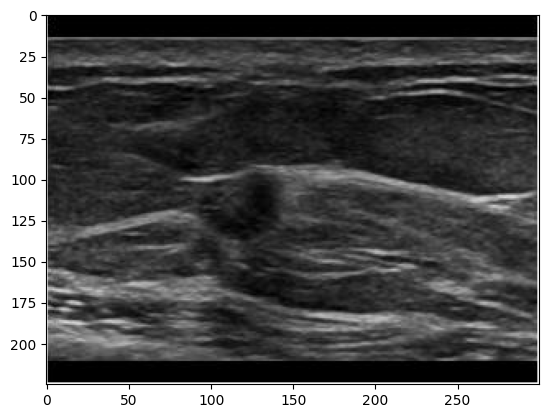

In [6]:
plt.imshow(img, cmap="gray")

In [7]:
img.shape

(225, 300)

In [8]:
img_cropped_path = os.path.join(raw_data_path, sample, sample_imgs[0])
img_cropped = read_breast_image(img_cropped_path)

In [9]:
img_cropped_path

'../../data/raw/BUSCoT/BUS-Expert/007373/007373@cropped.png'

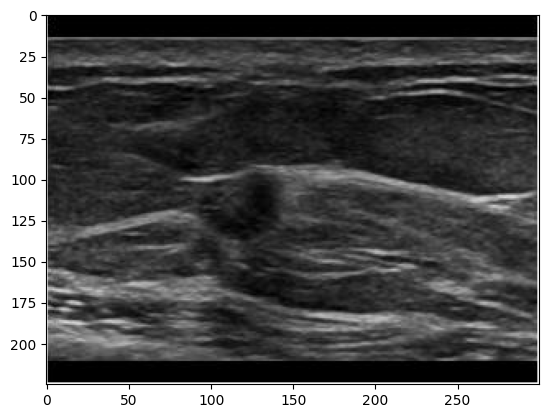

In [10]:
plt.imshow(img_cropped, cmap="gray")

In [121]:
def construct_csv_from_json(fp):
    with open(fp, "r") as open_file:
        json_content = json.load(open_file)


        pids = []
        datasets = []
        modalities = []
        patient_ids = []
        ages = []
        img_file_paths = []
        machines = []
        sides = []
        birads = []
        mass_margins_a = []
        mass_margins_b = []
        mass_echo = []

        for pid in tqdm(json_content, desc="Processing JSON", unit="pid", ncols=100, total=len(json_content)):
            pids.append(pid)
            datasets.append(json_content[pid]["dataset"])
            modalities.append(None if not json_content[pid]["modality"] else json_content[pid]["modality"])
            patient_ids.append(json_content[pid]["patient_id"])
            ages.append(json_content[pid]["age"])
            img_file_paths.append(json_content[pid]["image_file"]["raw_image"])
            machines.append(None if not json_content[pid]["device_type"] else json_content[pid]["device_type"])
            sides.append(None if not json_content[pid]["side"] else json_content[pid]["side"])

            lesion_info = json_content[pid]["us_report"]

            # go through the possible multiple lesions and just take the one with IsMainLesion set to True. If none are set to True, just take the first one.
            lesion_info = {k: v for k, v in lesion_info.items() if v.get("IsMainLesion", False) is True}
            if lesion_info:
                lesion_info = lesion_info[next(iter(lesion_info.keys()))]
            elif json_content[pid]["us_report"]:
                lesion_info = json_content[pid]["us_report"][next(iter(json_content[pid]["us_report"].keys()))]
            else:
                lesion_info = {}

            birads.append(lesion_info.get("BIRADS", None))
            mass_margins_a.append(lesion_info.get("LesionBoundary", None))
            mass_margins_b.append(lesion_info.get("LesionEdge", None))
            mass_echo.append(lesion_info.get("EchoCharacteristics", None))

    df = pd.DataFrame(
        {
            "pid": pids,
            "dataset": datasets,
            "modality": modalities,
            "patient_id": patient_ids,
            "age": ages,
            "img_file_path": img_file_paths,
            "machine": machines,
            "side": sides,
            "birads": birads,
            "mass_margins_a": mass_margins_a,
            "mass_margins_b": mass_margins_b,
            "mass_echo": mass_echo,
        }
    )
    return df

In [122]:
main_df = construct_csv_from_json(ds_files_expert_annotated)

Processing JSON: 100%|███████████████████████████████████| 11439/11439 [00:00<00:00, 798047.96pid/s]


In [123]:
main_df

,pid,dataset,modality,patient_id,age,img_file_path,machine,side,birads,mass_margins_a,mass_margins_b,mass_echo
0,000000,BUDIAT,US,BUDIAT@000001,-1,000000/000000@raw.png,NaN,NaN,2,BoundaryClear,Regular,LowEcho
1,000001,BUDIAT,US,BUDIAT@000002,-1,000001/000001@raw.png,NaN,NaN,2,BoundaryClear,Regular,LowEcho
2,000002,BUDIAT,US,BUDIAT@000003,-1,000002/000002@raw.png,NaN,NaN,2,BoundaryClear,Regular,LowEcho
3,000003,BUDIAT,US,BUDIAT@000004,-1,000003/000003@raw.png,NaN,NaN,2,BoundaryClear,Regular,LowEcho
4,000004,BUDIAT,US,BUDIAT@000005,-1,000004/000004@raw.png,NaN,NaN,2,BoundaryClear,Regular,LowEcho
...,...,...,...,...,...,...,...,...,...,...,...,...
11434,011006,PMC,NaN,PMC@000738,-1,011006/011006@raw.png,NaN,NaN,NaN,NaN,NaN,NaN
11435,009617,PMC,NaN,PMC@000738,-1,009617/009617@raw.png,NaN,NaN,NaN,NaN,NaN,NaN
11436,010770,PMC,NaN,PMC@000780,-1,010770/010770@raw.png,NaN,NaN,NaN,NaN,NaN,NaN
11437,009549,PMC,NaN,PMC@000781,-1,009549/009549@raw.png,NaN,NaN,NaN,NaN,NaN,NaN


In [124]:
main_df = main_df[main_df["birads"].notna()]
main_df

,pid,dataset,modality,patient_id,age,img_file_path,machine,side,birads,mass_margins_a,mass_margins_b,mass_echo
0,000000,BUDIAT,US,BUDIAT@000001,-1,000000/000000@raw.png,NaN,NaN,2,BoundaryClear,Regular,LowEcho
1,000001,BUDIAT,US,BUDIAT@000002,-1,000001/000001@raw.png,NaN,NaN,2,BoundaryClear,Regular,LowEcho
2,000002,BUDIAT,US,BUDIAT@000003,-1,000002/000002@raw.png,NaN,NaN,2,BoundaryClear,Regular,LowEcho
3,000003,BUDIAT,US,BUDIAT@000004,-1,000003/000003@raw.png,NaN,NaN,2,BoundaryClear,Regular,LowEcho
4,000004,BUDIAT,US,BUDIAT@000005,-1,000004/000004@raw.png,NaN,NaN,2,BoundaryClear,Regular,LowEcho
...,...,...,...,...,...,...,...,...,...,...,...,...
9446,009446,Web data,US,Web data@000769,-1,009446/009446@raw.png,NaN,NaN,4B,BoundaryClear,Irregular,LowEcho
9447,009447,Web data,US,Web data@000769,-1,009447/009447@raw.png,NaN,NaN,4A,BoundaryClear,Irregular,LowEcho
9450,009450,Web data,US,Web data@000888,-1,009450/009450@raw.png,NaN,NaN,4B,BoundaryUnclear,Irregular,LowEcho
9451,009451,Web data,Doppler,Web data@000888,-1,009451/009451@raw.png,NaN,NaN,4A,BoundarySomewhatUnclear,PartiallyRegular,HighEcho


In [125]:
from utils.preprocessing import (
    BIRADS_ASSESSMENT,
    get_value,
)

main_df["birads"] = main_df["birads"].apply(lambda x: get_value(x, BIRADS_ASSESSMENT))
main_df

,pid,dataset,modality,patient_id,age,img_file_path,machine,side,birads,mass_margins_a,mass_margins_b,mass_echo
0,000000,BUDIAT,US,BUDIAT@000001,-1,000000/000000@raw.png,NaN,NaN,benign,BoundaryClear,Regular,LowEcho
1,000001,BUDIAT,US,BUDIAT@000002,-1,000001/000001@raw.png,NaN,NaN,benign,BoundaryClear,Regular,LowEcho
2,000002,BUDIAT,US,BUDIAT@000003,-1,000002/000002@raw.png,NaN,NaN,benign,BoundaryClear,Regular,LowEcho
3,000003,BUDIAT,US,BUDIAT@000004,-1,000003/000003@raw.png,NaN,NaN,benign,BoundaryClear,Regular,LowEcho
4,000004,BUDIAT,US,BUDIAT@000005,-1,000004/000004@raw.png,NaN,NaN,benign,BoundaryClear,Regular,LowEcho
...,...,...,...,...,...,...,...,...,...,...,...,...
9446,009446,Web data,US,Web data@000769,-1,009446/009446@raw.png,NaN,NaN,suspicious,BoundaryClear,Irregular,LowEcho
9447,009447,Web data,US,Web data@000769,-1,009447/009447@raw.png,NaN,NaN,suspicious,BoundaryClear,Irregular,LowEcho
9450,009450,Web data,US,Web data@000888,-1,009450/009450@raw.png,NaN,NaN,suspicious,BoundaryUnclear,Irregular,LowEcho
9451,009451,Web data,Doppler,Web data@000888,-1,009451/009451@raw.png,NaN,NaN,suspicious,BoundarySomewhatUnclear,PartiallyRegular,HighEcho


In [126]:
main_df[main_df["mass_echo"].isna()]

,pid,dataset,modality,patient_id,age,img_file_path,machine,side,birads,mass_margins_a,mass_margins_b,mass_echo
764,000764,BUSBRA,US,BUSBRA@000318,-1,000764/000764@raw.png,GE Logiq 7 @10-14MHz,right,suspicious,BoundaryUnclear,Irregular,NaN
1799,001799,BUSBRA,US,BUSBRA@000997,-1,001799/001799@raw.png,GE Logiq 7 @10-14MHz,left,suspicious,BoundaryFairlyClear,PartiallyRegular,NaN
1952,001952,BUSBRA,US,BUSBRA@000027,-1,001952/001952@raw.png,Toshiba Aplio 300 @12-14 MHz,left,suspicious,BoundaryFairlyClear,PartiallyRegular,NaN
4102,004102,TFUSL,US,TFUSL@000038,-1,004102/004102@raw.png,GE-LOGIQ-E9,NaN,benign,BoundaryUnclear,NaN,NaN
4663,004663,TFUSL,US,TFUSL@000547,-1,004663/004663@raw.png,GE-LOGIQ-E9,NaN,probably benign,NaN,NaN,NaN
6447,006447,Web data,US,Web data@000653,-1,006447/006447@raw.png,NaN,NaN,suspicious,NaN,NaN,NaN
7118,007118,Web data,US,Web data@000526,-1,007118/007118@raw.png,NaN,NaN,benign,NaN,NaN,NaN
8120,008120,Web data,NoBreast,Web data@000228,-1,008120/008120@raw.png,NaN,NaN,benign,NaN,NaN,NaN
8420,008420,Web data,US,Web data@000857,-1,008420/008420@raw.png,NaN,NaN,probably benign,NaN,NaN,NaN
9142,009142,Web data,NoBreast,Web data@000018,-1,009142/009142@raw.png,NaN,NaN,probably benign,BoundaryClear,Regular,NaN


In [128]:
main_df["mass_margins_a"].value_counts(dropna=False)

mass_margins_a
BoundaryClear              2743
BoundaryUnclear            1491
BoundarySomewhatUnclear    1352
BoundaryFairlyClear        1133
NaN                           6
Name: count, dtype: int64

In [130]:
main_df["mass_margins_b"].value_counts(dropna=False)

mass_margins_b
Regular             2724
Irregular           2033
PartiallyRegular    1958
NaN                   10
Name: count, dtype: int64

In [131]:
main_df.groupby("mass_margins_a")["mass_margins_b"].value_counts(dropna=False)

mass_margins_a           mass_margins_b  
BoundaryClear            Regular             2261
                         PartiallyRegular     351
                         Irregular            129
                         NaN                    2
BoundaryFairlyClear      PartiallyRegular     625
                         Regular              286
                         Irregular            221
                         NaN                    1
BoundarySomewhatUnclear  PartiallyRegular     879
                         Irregular            303
                         Regular              170
BoundaryUnclear          Irregular           1380
                         PartiallyRegular     103
                         Regular                7
                         NaN                    1
Name: count, dtype: int64

In [64]:
# the mass echo is NaN for the datasets: PatternFigures, pmc, Birads-ultrasound 
# the birads is NaN for the datasets: PatternFigures, pmc, Birads-ultrasound
main_df["dataset"].value_counts(dropna=False)

dataset
Web data             3299
TFUSL                2472
BUSBRA               1875
PMC                  1641
TUHD                  886
BUSI                  780
BUDIAT                163
PatternFigures        109
Birads-ultrasound     100
ROCO                   72
STU-Hospital           42
Name: count, dtype: int64

In [84]:
main_df[main_df["modality"] == "NoBreast"]

,pid,dataset,modality,patient_id,age,img_file_path,machine,side,birads,mass_margins,mass_shapes,mass_echo
67,000067,BUDIAT,NoBreast,BUDIAT@000068,-1,000067/000067@raw.png,NaN,NaN,3,BoundaryClear,Regular,LowEcho
575,000575,BUSBRA,NoBreast,BUSBRA@000208,-1,000575/000575@raw.png,GE Logiq 7 @10-14MHz,left,NaN,NaN,NaN,NaN
2074,002074,ROCO,NoBreast,ROCO@000018,-1,002074/002074@raw.png,NaN,NaN,NaN,NaN,NaN,NaN
2900,002900,TUHD,NoBreast,TUHD@000149,-1,002900/002900@raw.png,NaN,NaN,NaN,NaN,NaN,NaN
2902,002902,TUHD,NoBreast,TUHD@000150,-1,002902/002902@raw.png,NaN,NaN,4B,BoundaryClear,Regular,SlightlyLowEcho
...,...,...,...,...,...,...,...,...,...,...,...,...
9312,009312,Web data,NoBreast,Web data@000362,-1,009312/009312@raw.png,NaN,NaN,NaN,NaN,NaN,NaN
9314,009314,Web data,NoBreast,Web data@000362,-1,009314/009314@raw.png,NaN,NaN,NaN,NaN,NaN,NaN
9318,009318,Web data,NoBreast,Web data@000491,-1,009318/009318@raw.png,NaN,NaN,NaN,NaN,NaN,NaN
9421,009421,Web data,NoBreast,Web data@000334,-1,009421/009421@raw.png,NaN,NaN,NaN,NaN,NaN,NaN


In [68]:
fo = open(ds_files_expert_annotated, "r")
data = json.load(fo)

In [95]:
data["000067"]

{'dataset': 'BUDIAT',
 'modality': 'NoBreast',
 'source_information': {'url': {'url': '', 'raw_page': None}, 'license': ''},
 'patient_id': 'BUDIAT@000068',
 'age': -1,
 'image_file': {'raw_image': '000067/000067@raw.png',
  'cropped_image': '000067/000067@cropped.png',
  'supre_resolution_image': ''},
 'lesion_mask_file': {},
 'device_type': '',
 'side': '',
 'pathology_histology': {'pathology': 'Benign',
  'subtype': {'cyst': {'histology': 'cyst',
    'histology xiehe': 'Other benign breast tumours',
    'ICD-O': None,
    'ICD-10': None,
    'ICD-11': None,
    'Gene': None}}},
 'lesion_box': {'0': [0.24720893141945774,
   0.13926174496644295,
   0.8373205741626795,
   0.2751677852348993]},
 'caption': {'image_relative_caption': '',
  'image_full_caption': '',
  'key_words': []},
 'us_report': {'0': {'ImageModality': 'NoBreast',
   'IsMainLesion': True,
   'LesionBoxNeedAdjust': False,
   'LesionMaskNeedAdjust': False,
   'BIRADS': '3',
   'LesionBoundary': 'BoundaryClear',
   'Lesi

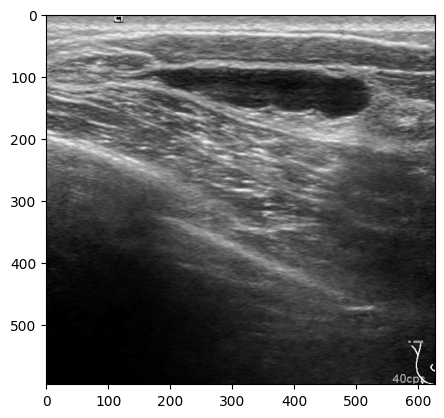

In [96]:
sample = "000067"
target_file = f"{sample}@raw.png"

img_path = os.path.join(raw_data_path, sample, target_file)
img = read_breast_image(img_path)
plt.imshow(img, cmap="gray")